1 NumPy

In [1]:
import numpy as np

a = np.array([2, 3, 4])
B = np.array([[1.2, 2, 4], [3.1, 4.0, 5]])

print(a.ndim)     # ilosc wymiarow tablicy
print(a.shape)    # ksztalt tablicy reprezentowany jako tuple
print(a.size)     # calkowita ilosc elementow
print(a.dtype)    # typ elementow
print(a.itemsize) # wielkosc elementu w bajtach

print(B.ndim)
print(B.shape)
print(B.size)
print(B.dtype)
print(B.itemsize)

dir(a)

1
(3,)
3
int64
8
2
(2, 3)
6
float64
8


['T',
 '__abs__',
 '__add__',
 '__and__',
 '__array__',
 '__array_finalize__',
 '__array_function__',
 '__array_interface__',
 '__array_namespace__',
 '__array_priority__',
 '__array_struct__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__class__',
 '__class_getitem__',
 '__complex__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__divmod__',
 '__dlpack__',
 '__dlpack_device__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__ilshift__',
 '__imatmul__',
 '__imod__',
 '__imul__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__irshift__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__or__',
 '__pos__

1.1 Czas operacji

In [2]:
import timeit

n = 1_000_000

lst = list(range(n)) # [0, 1, ..., n-1]
arr = np.arange(n)   # [0; 1; ...; n-1]

number = 100
repeat = 5

arr_times = timeit.repeat(
    "arr.sum()",
    globals=globals(),
    number=number,
    repeat=repeat,
)

lst_times = timeit.repeat(
    "sum(lst)",
    globals=globals(),
    number=number,
    repeat=repeat
)

def sum_own(lst):
    total_sum = 0

    for elem in lst:
        total_sum += elem

    return total_sum

lst_own_times = timeit.repeat(
    "sum_own(lst)",
    globals=globals(),
    number=number,
    repeat=repeat
)

print(sum(arr_times) / (number * repeat))
print(sum(lst_times) / (number * repeat))
print(sum(lst_own_times) / (number * repeat))

0.0004922661740006333
0.0048880174039995835
0.0367662462520002


1.2 Tworzenie tablic

In [3]:
C = np.ones((3, 2)) # np.zeros, np.ones, np.empty
d = np.linspace(start=0, stop=1, num=6)

1.3 Podstawowe operacje

In [4]:
E = B - 1
F = E * 2

# * - gwiazdka to iloczyn Hadamarda
# @ - malpa to mnozenie macierzy Cauchy'ego

print(E)
print(F)
print(B.tolist() * 2)

print(B.min())       # najmniejsza wartosc
print(B.max())       # najwieksza wartosc
print(B.sum())       # suma elementow
print(B.sum(axis=0)) # suma dla kazdej kolumny
print(B.sum(axis=1)) # suma dla kazdego wiersza

[[0.2 1.  3. ]
 [2.1 3.  4. ]]
[[0.4 2.  6. ]
 [4.2 6.  8. ]]
[[1.2, 2.0, 4.0], [3.1, 4.0, 5.0], [1.2, 2.0, 4.0], [3.1, 4.0, 5.0]]
1.2
5.0
19.3
[4.3 6.  9. ]
[ 7.2 12.1]


1.3.1 Zadanie do wykonania

In [5]:
print(E * B)
print(E @ C)

[[ 0.24  2.   12.  ]
 [ 6.51 12.   20.  ]]
[[4.2 4.2]
 [9.1 9.1]]


1.4 Ksztalt tablicy

In [6]:
from numpy.linalg import inv, det

print(d[2])    # element o indeksie 2
print(d[-1])   # ostatni element
print(B[1][2]) # wiersz o indeksie 1, kolumna o indeksie 2
print(d[2:5])  # od elem. 2 (razem z 2) do 5 (bez 5)
print(d[2:])   # od 2 (razem z 2)
print(d[:2])   # pierwsze dwa elementy

B.flatten()          # "splaszczenie" do wektora
B.reshape(6, 1)      # zmiana ksztaltu na podany
B.T                  # transpozycja
np.hsplit(B, 3)      # podzial poziomy
np.vstack((a, a-1))  # zlozenie pionowe
np.hstack((a, a*-1)) # zlozenie poziome

inv(B @ B.T)
det(B.T @ B)

0.4
1.0
5.0
[0.4 0.6 0.8]
[0.4 0.6 0.8 1. ]
[0.  0.2]


np.float64(-1.2335021892795278e-13)

1.4.1 Zadania do wykonania

In [7]:
d = d.reshape(3, 2)

t = np.arange(2, 8)
print(t[t % 2 == 0].sum())

temps = np.random.normal(
    loc=np.linspace(278, 303, 7)[:, None],
    scale=8,
    size=(7, 4)
)
temps[[1, 3], [2, 3]] = 0

temps_del = temps[temps > 0]
print(temps_del)
print(temps_del.shape)

print(temps)
for day in temps:
    day_sum = day[day != 0].sum()
    day_avg = day_sum / day[day != 0].size

    day[day == 0] = day_avg

temps = temps - 273.15
print(temps)

print("Ilosc pomiarow wiekszych od 25 stopni C: " + str(temps[temps > 25].size))
print("Ilosc pomiarow mniejszych od 0 stopni C: " + str(temps[temps < 0].size))


12
[288.41830661 275.48115597 281.9840152  269.12550382 278.30229902
 283.48770365 268.74789924 294.48832077 278.27048303 279.0880403
 287.46032976 285.09113371 303.0551694  286.40854019 304.39274622
 298.38917693 291.11239104 277.17074264 291.67831025 294.18207082
 304.52411771 300.24127896 306.74173978 302.63785047 303.0649712
 315.95044535]
(26,)
[[288.41830661 275.48115597 281.9840152  269.12550382]
 [278.30229902 283.48770365   0.         268.74789924]
 [294.48832077 278.27048303 279.0880403  287.46032976]
 [285.09113371 303.0551694  286.40854019   0.        ]
 [304.39274622 298.38917693 291.11239104 277.17074264]
 [291.67831025 294.18207082 304.52411771 300.24127896]
 [306.74173978 302.63785047 303.0649712  315.95044535]]
[[15.26830661  2.33115597  8.8340152  -4.02449618]
 [ 5.15229902 10.33770365  3.6959673  -4.40210076]
 [21.33832077  5.12048303  5.9380403  14.31032976]
 [11.94113371 29.9051694  13.25854019 18.3682811 ]
 [31.24274622 25.23917693 17.96239104  4.02074264]
 [18.52

2 Matplotlib

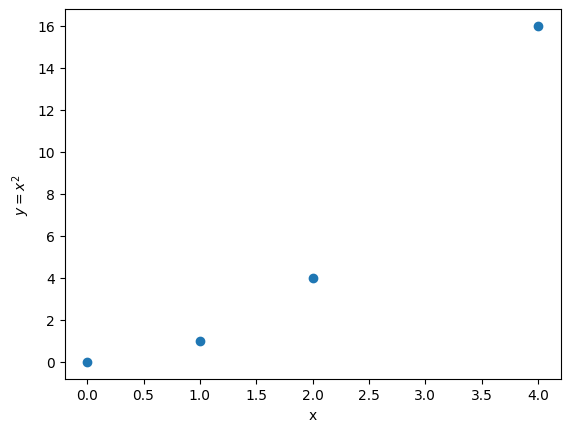

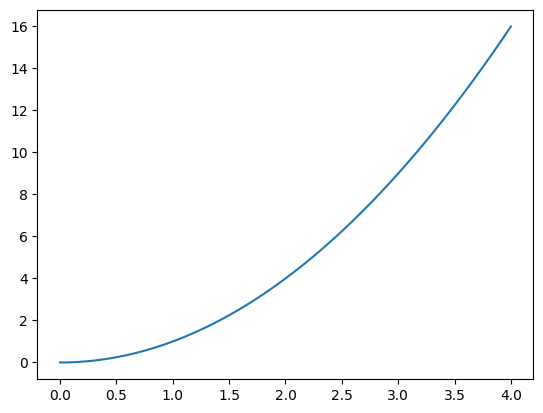

In [8]:
import matplotlib.pyplot as plt

x = [0, 1, 2, 4]
y = [0, 1, 4, 16]

plt.scatter(x, y)
plt.xlabel("x")
plt.ylabel("$y = x^2$") # LaTeX
plt.show()

x = np.linspace(0, 4, 100)
y = x**2

plt.plot(x, y)
plt.show()

2.1 Zadania do wykonania

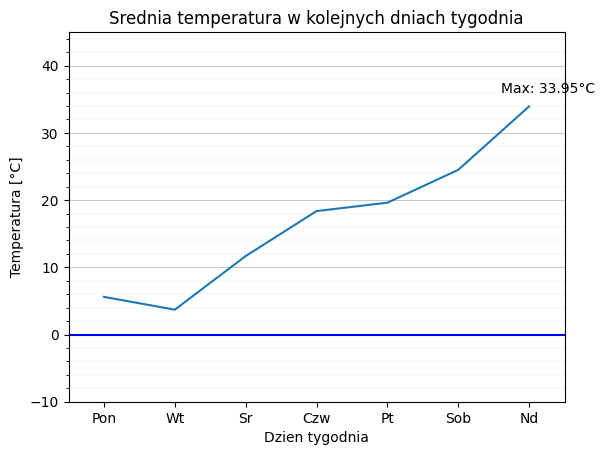

In [9]:
day_avg = temps.mean(axis=1)
days = ["Pon", "Wt", "Sr", "Czw", "Pt", "Sob", "Nd"]
max_temp = round(day_avg.max(), 2)
max_idx = np.argmax(day_avg)

x = range(temps.shape[0])
y = day_avg

plt.plot(x, y)
plt.title("Srednia temperatura w kolejnych dniach tygodnia")
plt.xlabel("Dzien tygodnia")
plt.ylabel("Temperatura [°C]")
plt.ylim(-10, 45)
plt.yticks(np.arange(-10, 45, 10), minor=False)
plt.yticks(np.arange(-10, 45, 2), minor=True)
plt.grid(which="major", axis="y", linewidth=0.5)
plt.grid(which="minor", axis="y", linewidth=0.1)
plt.xlim(-0.5, 6.5)
plt.xticks(range(temps.shape[0]), days)
plt.axline((0, 0), slope=0, color="blue")
plt.annotate(
    f"Max: {max_temp}°C",
    xy=(max_idx, max_temp),
    xytext=(-20, 10),
    textcoords="offset points"
)
plt.savefig("temperature.png", dpi=300)
plt.show()